# Imports and variables

In [ ]:
# Get imports and functions needed
%run BaseFiles/Imports.ipynb
%run BaseFiles/Functions.ipynb

## Data access
### Time frames - Define the start and end dates of the data that you want to look at (e.g. all 30 years between 1996 and 2026)
TimeFrames = ["1996-01-01 00:00", "2025-01-01 00:00"]

### Wind
DataSource = "Wind"
#### Places to get and save files
DataDirectory = "Data/windData/"
dataName = "wind_min_b"
PlotDirectory = "Plots/WindYearlyPlots/"

##### Details: Yearly, minutely data, bow-shock shifted

/home/rahyndman/miniforge3/envs/sunpyVenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-17 09:55:06 - spiceypy.utils.libspicehelper - INFO: Using fallback library next to module: /net/maedoc.ap.dias.ie/maedoc/home_cr/rahyndman/miniforge3/envs/sunpyVenv/lib/python3.14/site-packages/spiceypy/utils/libcspice.so


# Data Processing

## Read data to dataframes

In [2]:
dataTSStorage = [] # empty array for data

Start = TimeFrames[0] # start date of data
End = TimeFrames[1] # end date of data

#Separated by data source as files may have different file name conventions
if DataSource == "Wind": # If WIND data
    YearlyRange = Yearly(Start, End, frequency = 'MS') # Get range of dates needed (monthly as the downloaded data files are monthly)
    print(YearlyRange)
    for i in range(len(YearlyRange)-1): # for each date range in time range needed
        StartDate = YearlyRange[i] # first file in range
        # Below is a quick and unorganised way to deal with the varying number of days in months
        if YearlyRange[i][4:6] == "01" or YearlyRange[i][4:6] == "03" or YearlyRange[i][4:6] == "05" or YearlyRange[i][4:6] == "07" or YearlyRange[i][4:6] == "08" or YearlyRange[i][4:6] == "10" or YearlyRange[i][4:6] == "12":
            EndDate = YearlyRange[i][0:6] + "31" # last file in range
        elif YearlyRange[i][4:6] == "02":
            if YearlyRange[i][0:4] == "2000" or YearlyRange[i][0:4] == "2008" or YearlyRange[i][0:4] == "2016" or YearlyRange[i][0:4] == "2024":
                EndDate = YearlyRange[i][0:6] + "29" # last file in range
            else:
                EndDate = YearlyRange[i][0:6] + "28" # last file in range
        elif YearlyRange[i][4:6] == "04" or YearlyRange[i][4:6] == "06" or YearlyRange[i][4:6] == "09" or YearlyRange[i][4:6] == "11":
            EndDate = YearlyRange[i][0:6] + "30" # last file in range            
        # DateRange = ReadDates(StartDate, EndDate) # get date range
        dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
        dataTS = dfToSeries(dataFound) # convert to timeseries
        dataTS = AddTotVsw(dataTS) # add totvsw
        dataTS = AddBMag(dataTS) # add bmag
        # dataTS = AddLogBMag(dataTS) 
        # dataTS = AddLogBX(dataTS)
        dataTSStorage.append(dataTS) # add each month of data to the data array
        # StartAndEnd.append([StartDate, EndDate]) # add start and end dates to times array

else: # if not wind (or other coded sources)
    print("Data source not known") # give error message


['19960101', '19960201', '19960301', '19960401', '19960501', '19960601', '19960701', '19960801', '19960901', '19961001', '19961101', '19961201', '19970101', '19970201', '19970301', '19970401', '19970501', '19970601', '19970701', '19970801', '19970901', '19971001', '19971101', '19971201', '19980101', '19980201', '19980301', '19980401', '19980501', '19980601', '19980701', '19980801', '19980901', '19981001', '19981101', '19981201', '19990101', '19990201', '19990301', '19990401', '19990501', '19990601', '19990701', '19990801', '19990901', '19991001', '19991101', '19991201', '20000101', '20000201', '20000301', '20000401', '20000501', '20000601', '20000701', '20000801', '20000901', '20001001', '20001101', '20001201', '20010101', '20010201', '20010301', '20010401', '20010501', '20010601', '20010701', '20010801', '20010901', '20011001', '20011101', '20011201', '20020101', '20020201', '20020301', '20020401', '20020501', '20020601', '20020701', '20020801', '20020901', '20021001', '20021101', '20

In [3]:
listOfDF = [] # create a list for the data frames
for i in range(len(dataTSStorage)): #for each monthly dataframe
    listOfDF.append(dataTSStorage[i].to_dataframe()) # add them to the list

dataTSConcat = pd.concat(listOfDF) # concatenate all the monthly dataframes together to make one large dataframe for the full data timespan

In [4]:
print(dataTSConcat)

                     Year  DOY  Hour  Minute  IMF_PTS  PercentInterp  \
DateTime                                                               
1996-01-01 00:00:00  1996    1     0       0      2.0          100.0   
1996-01-01 00:01:00  1996    1     0       1      2.0          100.0   
1996-01-01 00:02:00  1996    1     0       2      1.0          100.0   
1996-01-01 00:03:00  1996    1     0       3      1.0          100.0   
1996-01-01 00:04:00  1996    1     0       4      1.0          100.0   
...                   ...  ...   ...     ...      ...            ...   
2024-12-31 23:55:00  2024  366    23      55      NaN            NaN   
2024-12-31 23:56:00  2024  366    23      56      1.0          100.0   
2024-12-31 23:57:00  2024  366    23      57      1.0          100.0   
2024-12-31 23:58:00  2024  366    23      58      NaN            NaN   
2024-12-31 23:59:00  2024  366    23      59      1.0          100.0   

                     CP/MVFlag  Timeshift  PFN_XGSE  PFN_YGSE  

In [5]:
# x = (2026-1996) * 365.25 * 24 * 60
# print(x)

In [ ]:
dataTSConcat.to_csv(str(DataSource) + "_" + str(Start)[0:11] + "-" + str(End)[0:11]+ ".csv")

In [7]:
AllYears = pd.read_csv("TestAllData.csv")

<Axes: >

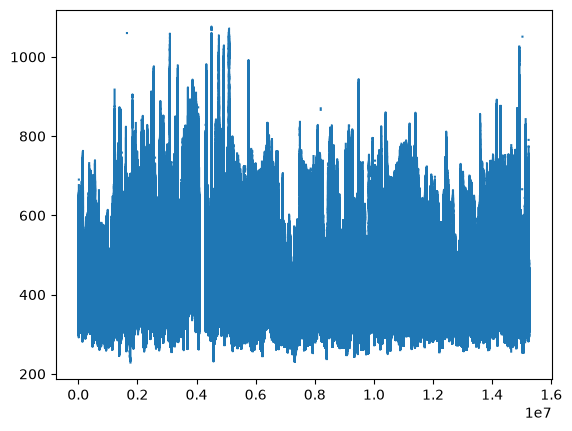

In [8]:
# Test that the full data range is plotted
AllYears["TotVsw"].plot()